# Iris Classification: a step-by-step ML walkthrough

Hello there :) I am Emanuele, a biomedical engineer who got curious about machine learning and AI.
This is my first GitHub project: I use it to learn the fundamentals and apply them directly in code.

**Pipeline**

1. Dataset basics
2. Data exploration
3. Distribution analysis
4. Relationship analysis
5. Train/test split
6. Hyperparameter tuning
7. Model comparison with nested cross-validation
8. Final evaluation on the test set (confusion matrix, ROC)

**Methodological rules followed in this version**

- The scaler lives *inside* a `Pipeline`, so it is fitted only on training data (no leakage).
- Models are compared with **nested cross-validation** (tuning inside, evaluation outside), so the scores are not optimistic.
- The **test set is used only once**, for the model chosen with cross-validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import randint

from sklearn.datasets import load_iris
from sklearn.model_selection import (
    KFold, StratifiedKFold, LeaveOneOut,
    GridSearchCV, RandomizedSearchCV, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay, roc_curve, auc,
)

try:  # nicer tables in Jupyter/Kaggle, plain print in a normal script
    from IPython.display import display
except ImportError:
    display = print

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')
SEED = 42  # makes every random step reproducible

## Task 1: Dataset basics

In [2]:
iris = load_iris()
features = iris.feature_names

dataframe = pd.DataFrame(iris.data, columns=features)
dataframe['species'] = iris.target_names[iris.target]

print("First 5 rows:")
display(dataframe.head())

print("Summary statistics:")
display(dataframe.describe())

print("DataFrame structure:")
dataframe.info()

print(f"\nShape (rows, columns): {dataframe.shape}")
print(f"\nMissing values per column:\n{dataframe.isnull().sum()}")
print(f"\nSamples per class:\n{dataframe['species'].value_counts()}")

First 5 rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Summary statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


DataFrame structure:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Shape (rows, columns): (150, 5)

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Samples per class:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Task 2: Data exploration

In [3]:
print("Mean, median and standard deviation per feature:")
display(dataframe[features].agg(['mean', 'median', 'std']).T.round(3))

print("Mean of each feature per species:")
display(dataframe.groupby('species')[features].mean().round(2))

# Outliers with the IQR rule (1.5 * IQR beyond the quartiles)
q1, q3 = dataframe[features].quantile(0.25), dataframe[features].quantile(0.75)
iqr = q3 - q1
is_outlier = (dataframe[features] < q1 - 1.5 * iqr) | (dataframe[features] > q3 + 1.5 * iqr)
print("Outliers per feature (IQR rule):")
print(is_outlier.sum())

Mean, median and standard deviation per feature:


,mean,median,std
sepal length (cm),5.843,5.80,0.828
sepal width (cm),3.057,3.00,0.436
petal length (cm),3.758,4.35,1.765
petal width (cm),1.199,1.30,0.762


Mean of each feature per species:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


Outliers per feature (IQR rule):
sepal length (cm)    0
sepal width (cm)     4
petal length (cm)    0
petal width (cm)     0
dtype: int64


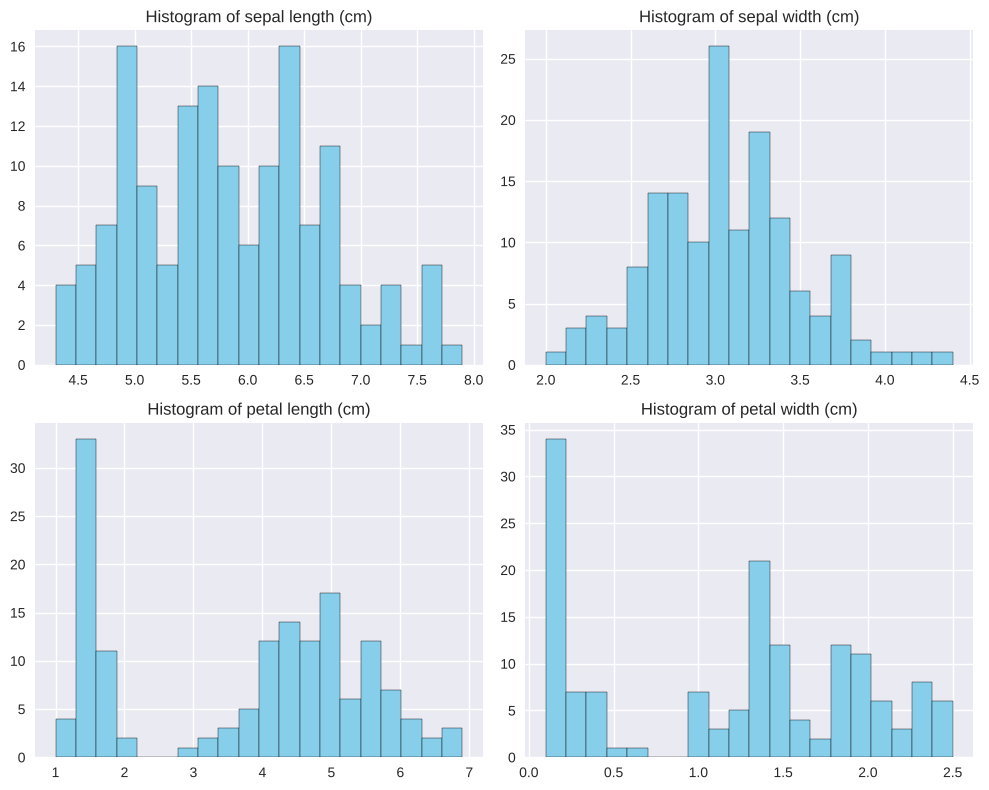

In [4]:
# Histograms
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, column in zip(axes.ravel(), features):
    ax.hist(dataframe[column], bins=20, color='skyblue', edgecolor='black')
    ax.set_title(f'Histogram of {column}')
plt.tight_layout()
plt.show()

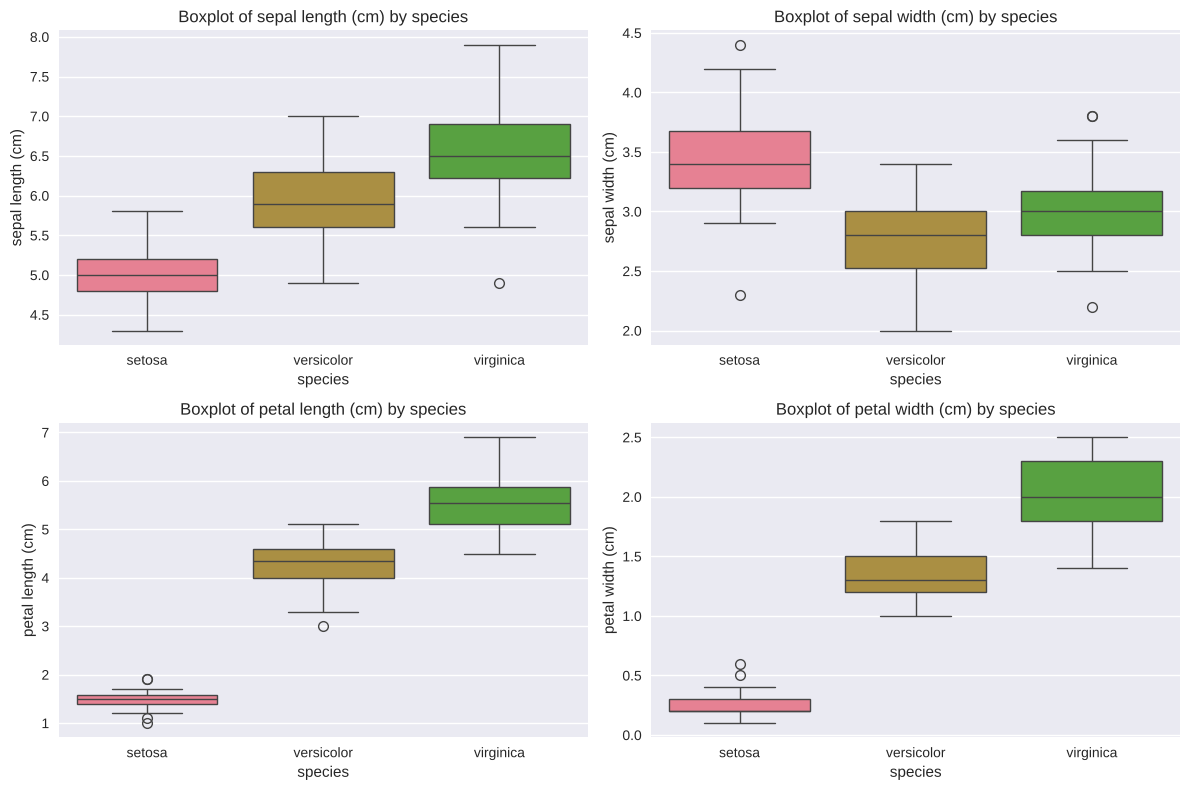

In [5]:
# Boxplots by species
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.ravel(), features):
    sns.boxplot(x='species', y=column, hue='species', data=dataframe, legend=False, ax=ax)
    ax.set_title(f'Boxplot of {column} by species')
plt.tight_layout()
plt.show()

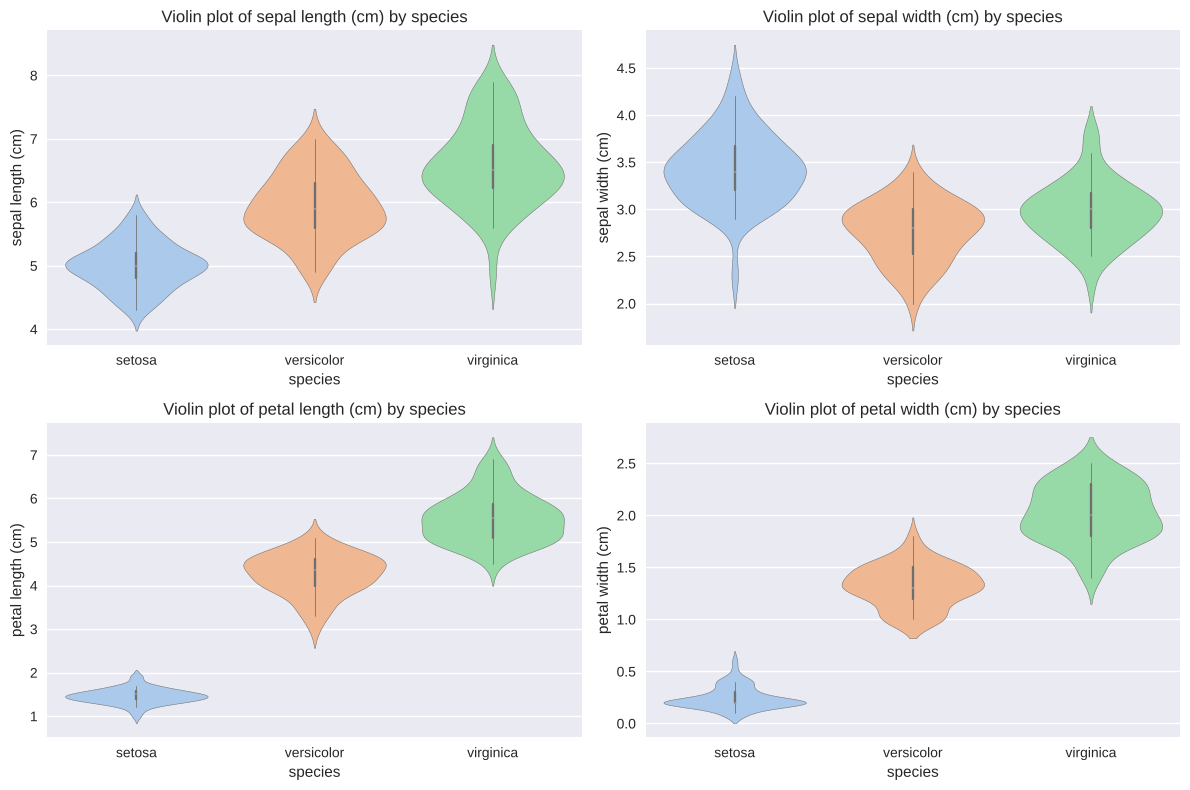

In [6]:
# Violin plots by species
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.ravel(), features):
    sns.violinplot(x='species', y=column, hue='species', data=dataframe,
                   palette='pastel', legend=False, ax=ax)
    ax.set_title(f'Violin plot of {column} by species')
plt.tight_layout()
plt.show()

## Task 3: Distribution analysis

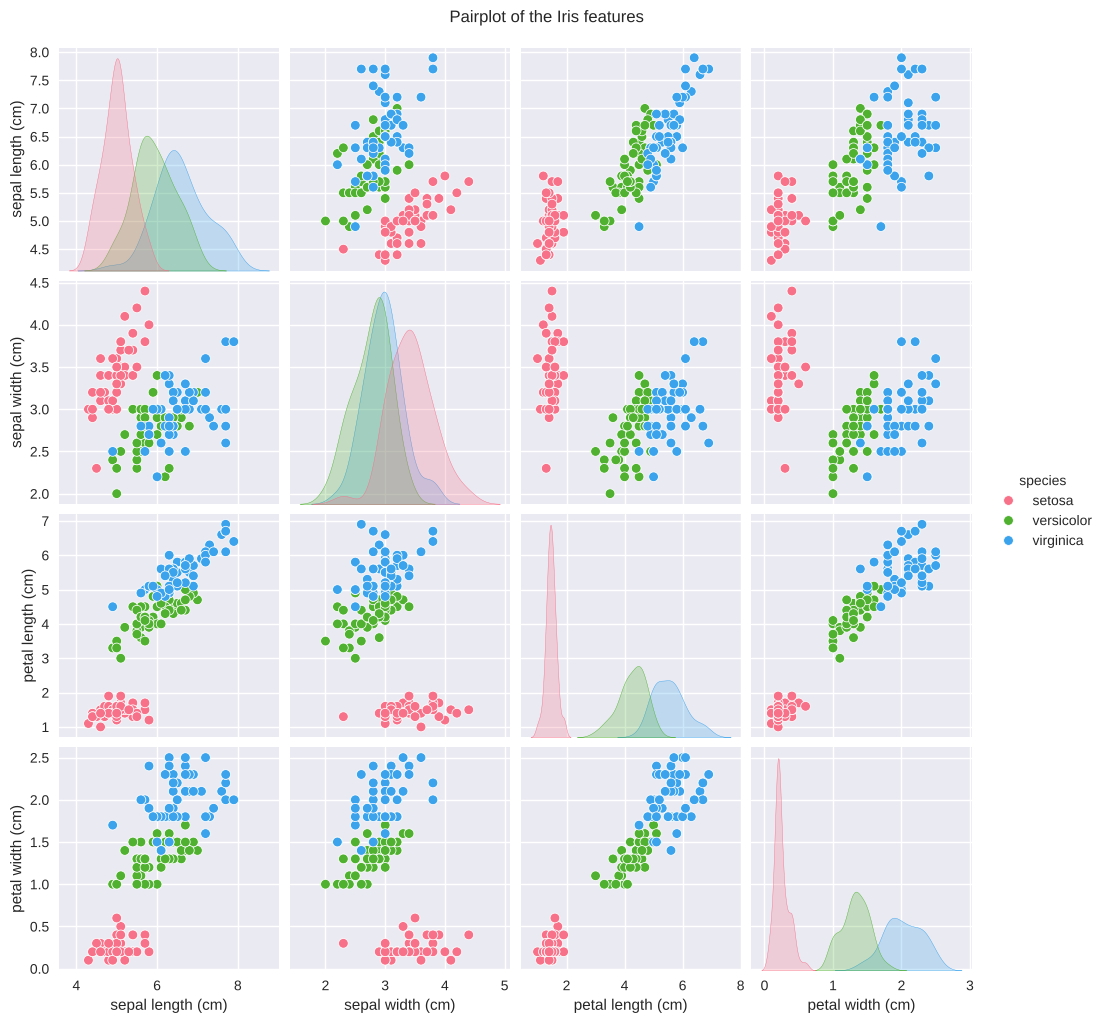

In [7]:
sns.pairplot(dataframe, hue='species', palette='husl')
plt.suptitle('Pairplot of the Iris features', y=1.02)
plt.show()

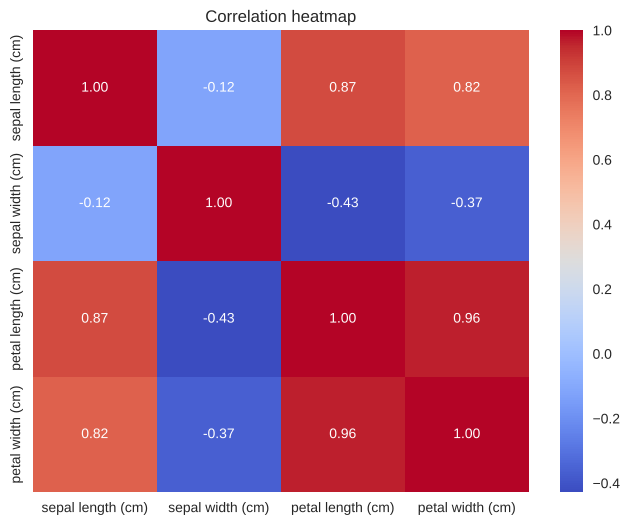

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(dataframe[features].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation heatmap')
plt.show()

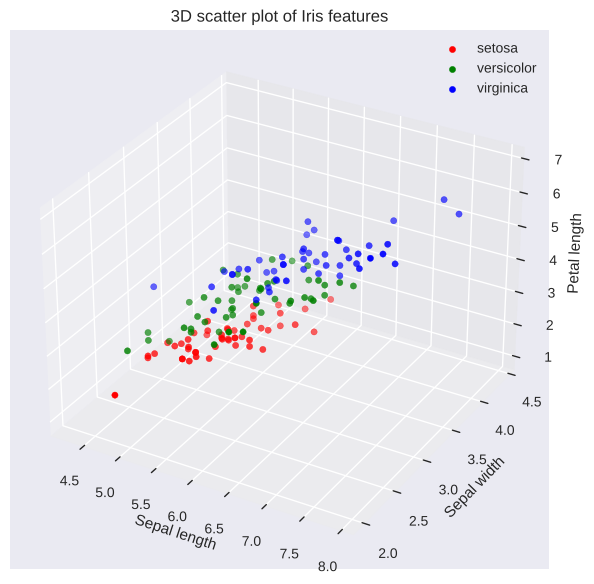

In [9]:
# 3D scatter plot (sepal length, sepal width, petal length)
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
colors = {'setosa': 'red', 'versicolor': 'green', 'virginica': 'blue'}
for species_name, group in dataframe.groupby('species'):
    ax.scatter(group['sepal length (cm)'], group['sepal width (cm)'], group['petal length (cm)'],
               label=species_name, color=colors[species_name])
ax.set_xlabel('Sepal length')
ax.set_ylabel('Sepal width')
ax.set_zlabel('Petal length')
ax.set_title('3D scatter plot of Iris features')
ax.legend()
plt.show()

## Task 4: Relationship analysis

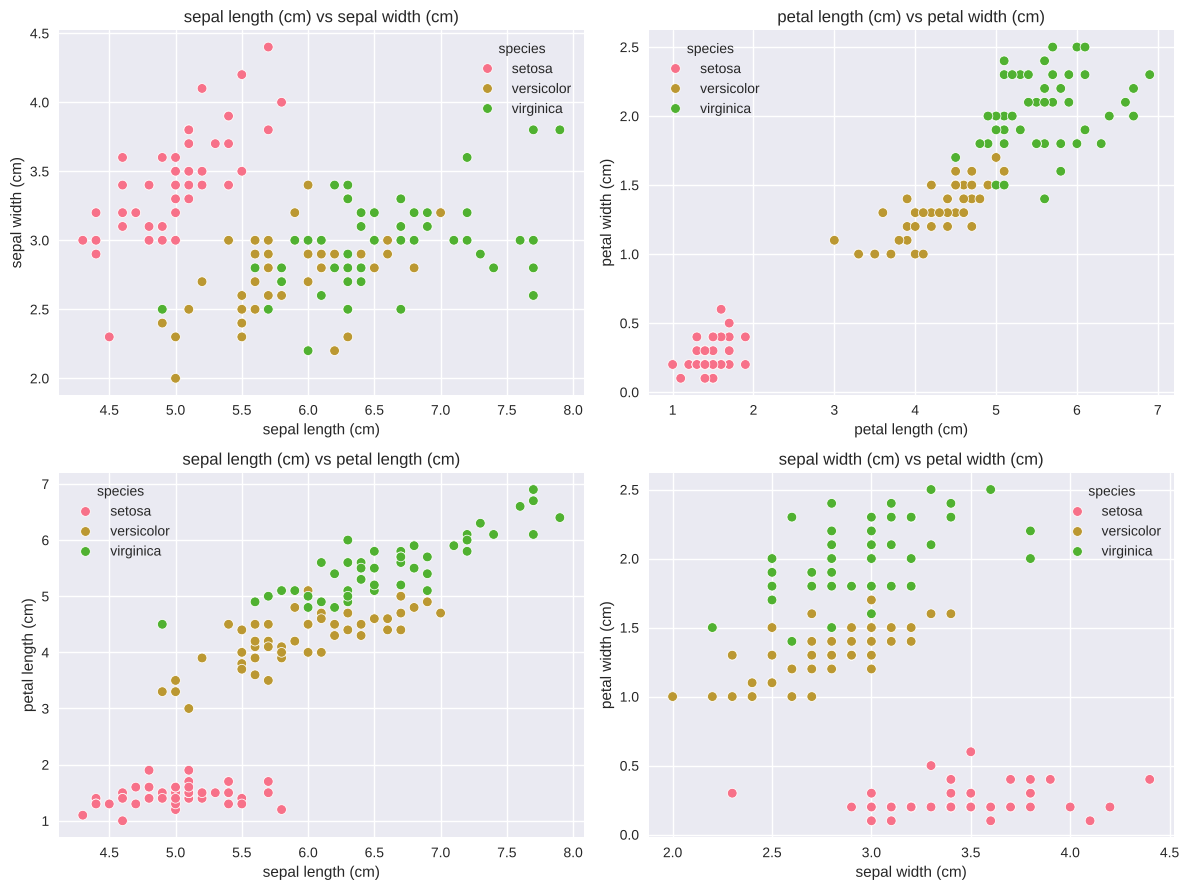

In [10]:
pairs = [
    ('sepal length (cm)', 'sepal width (cm)'),
    ('petal length (cm)', 'petal width (cm)'),
    ('sepal length (cm)', 'petal length (cm)'),
    ('sepal width (cm)', 'petal width (cm)'),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (x_col, y_col) in zip(axes.ravel(), pairs):
    sns.scatterplot(data=dataframe, x=x_col, y=y_col, hue='species', ax=ax)
    ax.set_title(f'{x_col} vs {y_col}')
    ax.grid(True)
plt.tight_layout()
plt.show()

## Task 5: Train/test split

Stratified 80/20 split. The scaler is **not** fitted here: it is part of each model pipeline below,
so during cross-validation it only ever sees the training folds.

In [11]:
X = dataframe[features]
y = dataframe['species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=SEED,  # same split at every run
    stratify=y,         # same class proportions in both sets
)

print(f"Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")
print("\nClass counts in train:")
print(y_train.value_counts())
print("\nClass counts in test:")
print(y_test.value_counts())

Train: 120 samples | Test: 30 samples

Class counts in train:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Class counts in test:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## Task 6: Hyperparameter tuning

Each model is wrapped in a search (`GridSearchCV` or `RandomizedSearchCV`) with 5-fold stratified cross-validation.
Compared to the first version:

- `liblinear` removed from the Logistic Regression grid (it does not support multiclass in recent scikit-learn versions, so half of the fits failed silently);
- the SVM grid is split by kernel, because `gamma` has no effect on the linear kernel, and `C` now goes lower;
- Decision Tree and KNN are now actually tuned (they were placeholders).

In [12]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

searches = {
    'Logistic Regression': GridSearchCV(
        Pipeline([('scaler', StandardScaler()),
                  ('model', LogisticRegression(max_iter=1000, random_state=SEED))]),
        {'model__C': [0.01, 0.1, 1, 10, 100],
         'model__solver': ['lbfgs', 'newton-cg']},
        cv=inner_cv, scoring='accuracy', n_jobs=-1),

    'Decision Tree': GridSearchCV(
        DecisionTreeClassifier(random_state=SEED),
        {'max_depth': [2, 3, 4, 5, None],
         'min_samples_leaf': [1, 2, 4, 8],
         'criterion': ['gini', 'entropy']},
        cv=inner_cv, scoring='accuracy', n_jobs=-1),

    'Random Forest': RandomizedSearchCV(
        RandomForestClassifier(random_state=SEED),
        {'n_estimators': randint(50, 200),
         'max_depth': randint(3, 15),
         'min_samples_leaf': randint(1, 10),
         'criterion': ['gini', 'entropy']},
        n_iter=30, cv=inner_cv, scoring='accuracy', n_jobs=-1, random_state=SEED),

    'SVM': GridSearchCV(
        Pipeline([('scaler', StandardScaler()),
                  ('model', SVC(random_state=SEED))]),
        [{'model__kernel': ['linear'],
          'model__C': [0.01, 0.1, 1, 10, 100]},
         {'model__kernel': ['rbf'],
          'model__C': [0.1, 1, 10, 100],
          'model__gamma': [0.001, 0.01, 0.1, 1]}],
        cv=inner_cv, scoring='accuracy', n_jobs=-1),

    'KNN': GridSearchCV(
        Pipeline([('scaler', StandardScaler()),
                  ('model', KNeighborsClassifier())]),
        {'model__n_neighbors': [1, 3, 5, 7, 9, 11, 15],
         'model__weights': ['uniform', 'distance'],
         'model__p': [1, 2]},
        cv=inner_cv, scoring='accuracy', n_jobs=-1),
}

tuning_rows = []
for name, search in searches.items():
    search.fit(X_train, y_train)
    tuning_rows.append({'Model': name,
                        'Best inner-CV accuracy': round(search.best_score_, 4),
                        'Best parameters': search.best_params_})

pd.set_option('display.max_colwidth', None)
display(pd.DataFrame(tuning_rows).set_index('Model'))

,Best inner-CV accuracy,Best parameters
Model,,
Logistic Regression,0.9667,"{'model__C': 10, 'model__solver': 'lbfgs'}"
Decision Tree,0.9583,"{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}"
Random Forest,0.9667,"{'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 8, 'n_estimators': 70}"
SVM,0.9750,"{'model__C': 0.1, 'model__kernel': 'linear'}"
KNN,0.9667,"{'model__n_neighbors': 3, 'model__p': 2, 'model__weights': 'uniform'}"


> The scores above are the *maximum* over many tried configurations, so they are slightly optimistic.
> The honest comparison comes next: nested cross-validation.

## Task 7: Model comparison with nested cross-validation

Each search object (tuning **and** fitting) is evaluated in an outer 5-fold stratified loop:
in every outer fold the hyperparameters are tuned only on that fold's training part, and the score is measured on data
the tuning never saw. This estimates how the *whole procedure* will generalize.

In [13]:
class CrossValidationAnalyzer:
    def __init__(self, models, cv_strategy='stratified_kfold', n_splits=5,
                 random_state=SEED, shuffle=True):
        self.models = models
        self.cv_strategy = cv_strategy
        self.n_splits = n_splits
        self.random_state = random_state
        self.shuffle = shuffle

        self.cv_results = {}    # summary statistics per model and metric
        self.fold_results = {}  # fold-by-fold test scores
        self.cv_splitter = self._setup_cv_strategy()

    def _setup_cv_strategy(self):
        if self.cv_strategy == 'kfold':
            return KFold(n_splits=self.n_splits, shuffle=self.shuffle,
                         random_state=self.random_state)
        elif self.cv_strategy == 'stratified_kfold':
            return StratifiedKFold(n_splits=self.n_splits, shuffle=self.shuffle,
                                   random_state=self.random_state)
        elif self.cv_strategy == 'leave_one_out':
            return LeaveOneOut()
        raise ValueError(f"Unknown CV strategy: {self.cv_strategy}")

    def perform_cv(self, X, y, scoring_metrics=None):
        if scoring_metrics is None:
            scoring_metrics = {
                'accuracy': 'accuracy',
                'precision': 'precision_weighted',
                'recall': 'recall_weighted',
                'f1': 'f1_weighted',
            }
        print(f"Performing {self.cv_strategy} cross-validation "
              f"({self.n_splits} folds)" if self.cv_strategy != 'leave_one_out'
              else "Performing leave-one-out cross-validation")
        print("-" * 50)

        for model_name, model in self.models.items():
            print(f"Evaluating {model_name}...")
            cv_out = cross_validate(model, X, y, cv=self.cv_splitter,
                                    scoring=scoring_metrics, return_train_score=True)

            summary = {}
            for metric in scoring_metrics:
                test_scores = cv_out[f'test_{metric}']
                train_scores = cv_out[f'train_{metric}']
                summary[metric] = {
                    'test_mean': test_scores.mean(),
                    'test_std': test_scores.std(),
                    'test_min': test_scores.min(),
                    'test_max': test_scores.max(),
                    'train_mean': train_scores.mean(),
                    'train_std': train_scores.std(),
                    'overfitting_gap': train_scores.mean() - test_scores.mean(),
                }
            self.cv_results[model_name] = summary
            self.fold_results[model_name] = {
                metric: cv_out[f'test_{metric}'] for metric in scoring_metrics
            }

        print("Cross-validation completed!")
        return self.cv_results

    def get_cv_summary(self, metric='accuracy'):
        rows = []
        for model_name, results in self.cv_results.items():
            rows.append({
                'Model': model_name,
                'Mean': results[metric]['test_mean'],
                'Std': results[metric]['test_std'],
                'Min': results[metric]['test_min'],
                'Max': results[metric]['test_max'],
                'Overfitting_Gap': results[metric]['overfitting_gap'],
            })
        # Ties on the mean are broken by lower std, then by lower overfitting gap
        return (pd.DataFrame(rows)
                .sort_values(['Mean', 'Std', 'Overfitting_Gap'], ascending=[False, True, True])
                .reset_index(drop=True))

    def get_best_model(self, metric='accuracy'):
        return self.get_cv_summary(metric).iloc[0]['Model']

    def plot_cv_results(self, metric='accuracy', figsize=(14, 6)):
        rows = [{'Model': name, 'Fold': fold + 1, 'Score': score}
                for name, scores in self.fold_results.items()
                for fold, score in enumerate(scores[metric])]
        plot_df = pd.DataFrame(rows)

        fig, axes = plt.subplots(1, 2, figsize=figsize)
        sns.boxplot(data=plot_df, x='Model', y='Score', hue='Model', legend=False, ax=axes[0])
        axes[0].set_title(f'{metric.capitalize()} distribution across outer folds')
        axes[0].tick_params(axis='x', rotation=45)

        for name, scores in self.fold_results.items():
            axes[1].plot(range(1, len(scores[metric]) + 1), scores[metric], marker='o', label=name)
        axes[1].set_xlabel('Fold')
        axes[1].set_ylabel(f'{metric.capitalize()}')
        axes[1].set_title(f'{metric.capitalize()} by fold')
        axes[1].set_xticks(range(1, self.n_splits + 1))
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    def plot_overfitting_analysis(self, figsize=(18, 5)):
        models = list(self.cv_results.keys())
        metrics = list(self.cv_results[models[0]].keys())
        fig, axes = plt.subplots(1, len(metrics), figsize=figsize)
        x = np.arange(len(models))
        width = 0.35
        for ax, metric in zip(np.atleast_1d(axes), metrics):
            train_means = [self.cv_results[m][metric]['train_mean'] for m in models]
            test_means = [self.cv_results[m][metric]['test_mean'] for m in models]
            ax.bar(x - width / 2, train_means, width, label='Train', alpha=0.7)
            ax.bar(x + width / 2, test_means, width, label='Validation', alpha=0.7)
            ax.set_ylim(0.8, 1.02)
            ax.set_title(f'{metric.capitalize()}: train vs validation')
            ax.set_xticks(x)
            ax.set_xticklabels(models, rotation=45, ha='right')
            ax.legend()
            ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    def get_statistical_significance(self, model1, model2, metric='accuracy', alpha=0.05):
        # Paired t-test on the outer-fold scores. Folds share data, so treat the p-value as indicative only.
        scores1 = self.fold_results[model1][metric]
        scores2 = self.fold_results[model2][metric]
        if np.allclose(scores1, scores2):
            t_stat, p_value = 0.0, 1.0  # identical scores: the t-test would return NaN
        else:
            t_stat, p_value = stats.ttest_rel(scores1, scores2)
        return {
            'model1': model1,
            'model2': model2,
            'metric': metric,
            't_statistic': t_stat,
            'p_value': p_value,
            'significant': p_value < alpha,
            'better_model': model1 if np.mean(scores1) >= np.mean(scores2) else model2,
        }

    def export_results(self, filename='cv_results.csv'):
        rows = []
        for model_name, results in self.cv_results.items():
            for metric, values in results.items():
                rows.append({'Model': model_name, 'Metric': metric, **values})
        pd.DataFrame(rows).to_csv(filename, index=False)
        print(f"Results exported to {filename}")

In [14]:
analyzer = CrossValidationAnalyzer(searches)
analyzer.perform_cv(X_train, y_train)

Performing stratified_kfold cross-validation (5 folds)
--------------------------------------------------
Evaluating Logistic Regression...


Evaluating Decision Tree...


Evaluating Random Forest...


Evaluating SVM...


Evaluating KNN...


Cross-validation completed!


{'Logistic Regression': {'accuracy': {'test_mean': np.float64(0.9583333333333334),
   'test_std': np.float64(0.026352313834736508),
   'test_min': np.float64(0.9166666666666666),
   'test_max': np.float64(1.0),
   'train_mean': np.float64(0.9770833333333334),
   'train_std': np.float64(0.016666666666666653),
   'overfitting_gap': np.float64(0.018750000000000044)},
  'precision': {'test_mean': np.float64(0.9644444444444444),
   'test_std': np.float64(0.02115978793642329),
   'test_min': np.float64(0.9333333333333332),
   'test_max': np.float64(1.0),
   'train_mean': np.float64(0.9771464646464647),
   'train_std': np.float64(0.01671442499330596),
   'overfitting_gap': np.float64(0.01270202020202027)},
  'recall': {'test_mean': np.float64(0.9583333333333334),
   'test_std': np.float64(0.026352313834736508),
   'test_min': np.float64(0.9166666666666666),
   'test_max': np.float64(1.0),
   'train_mean': np.float64(0.9770833333333334),
   'train_std': np.float64(0.016666666666666653),
   'ov

In [15]:
print("Nested CV summary (accuracy):")
display(analyzer.get_cv_summary('accuracy').round(4))

Nested CV summary (accuracy):


,Model,Mean,Std,Min,Max,Overfitting_Gap
0,SVM,0.9667,0.0312,0.9167,1.0000,0.0083
1,Random Forest,0.9667,0.0312,0.9167,1.0000,0.0104
2,Logistic Regression,0.9583,0.0264,0.9167,1.0000,0.0188
3,KNN,0.9583,0.0264,0.9167,1.0000,0.0250
4,Decision Tree,0.9417,0.0204,0.9167,0.9583,0.0417


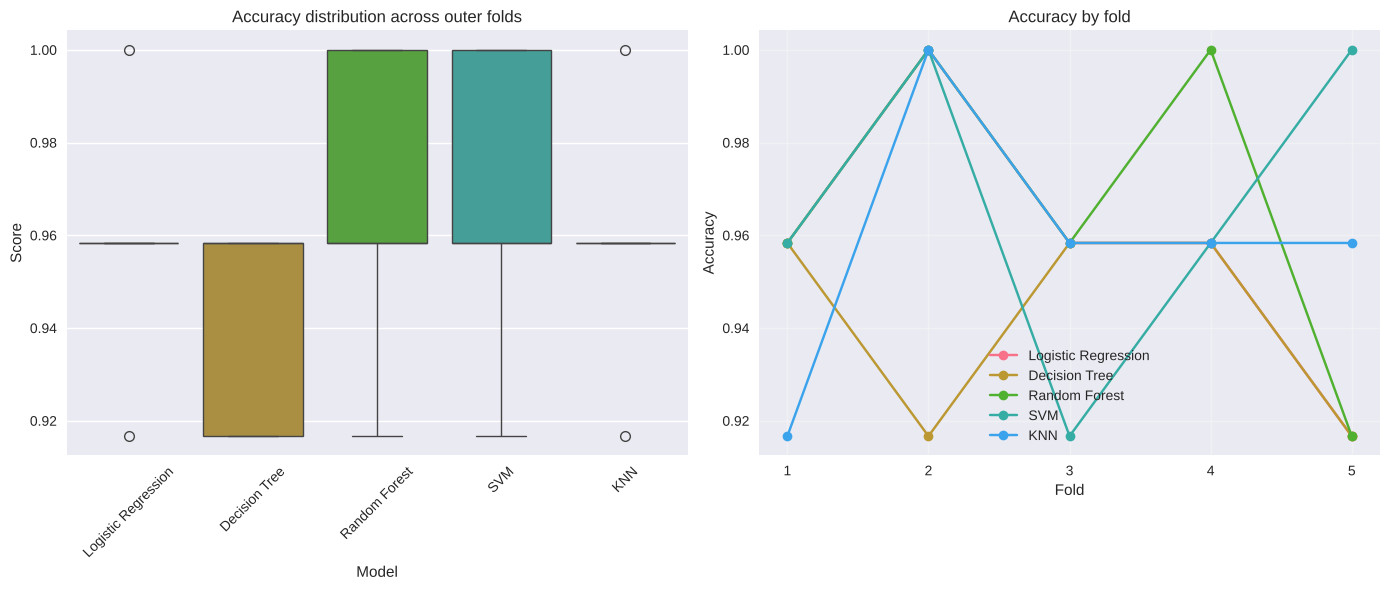

In [16]:
analyzer.plot_cv_results('accuracy')

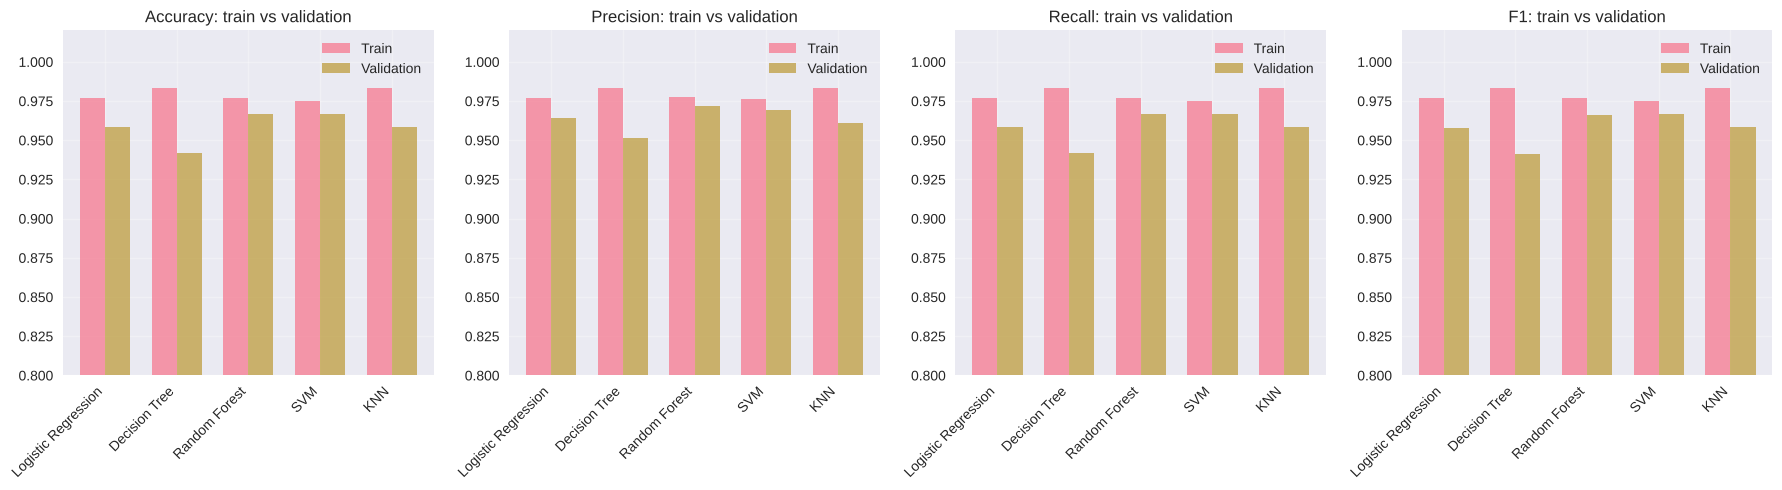

In [17]:
analyzer.plot_overfitting_analysis()

In [18]:
summary = analyzer.get_cv_summary('accuracy')
first, second = summary.iloc[0]['Model'], summary.iloc[1]['Model']
print(f"Top two models: {first} vs {second}")
display(pd.Series(analyzer.get_statistical_significance(first, second)).to_frame('value'))

Top two models: SVM vs Random Forest


,value
model1,SVM
model2,Random Forest
metric,accuracy
t_statistic,0.0
p_value,1.0
significant,False
better_model,SVM


In [19]:
analyzer.export_results('cv_results.csv')

Results exported to cv_results.csv


## Task 8: Final evaluation on the test set

The model is chosen with the nested cross-validation above, **not** by looking at the test set.
The test set is used here once, on the winner only. With 30 test samples, one mistake already moves accuracy by about 3 points, so treat this number with care.

In [20]:
best_name = analyzer.get_best_model('accuracy')
final_model = searches[best_name].best_estimator_  # tuned and refitted on the full training set
print(f"Selected model: {best_name}")
print(f"Best parameters: {searches[best_name].best_params_}\n")

y_pred = final_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred))

Selected model: SVM
Best parameters: {'model__C': 0.1, 'model__kernel': 'linear'}

Test accuracy: 0.9333

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



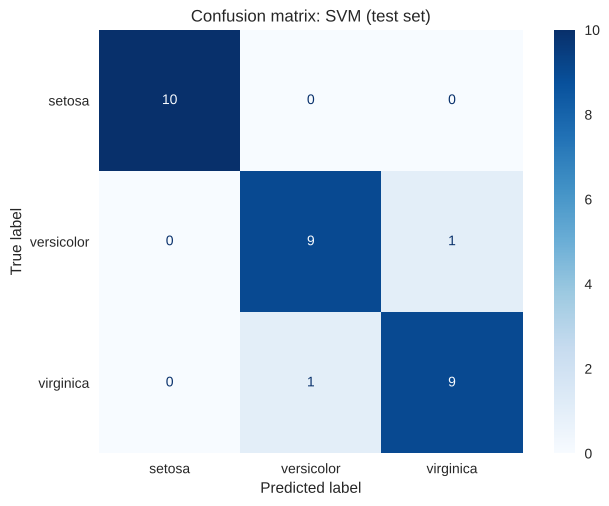

In [21]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title(f'Confusion matrix: {best_name} (test set)')
plt.grid(False)
plt.show()

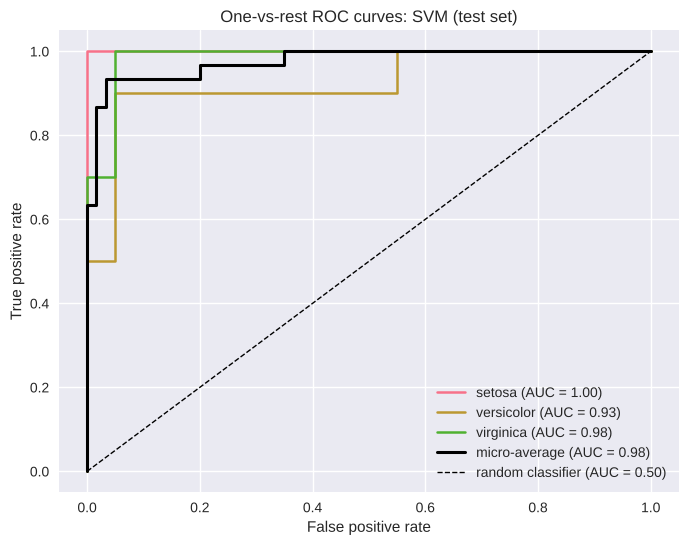

In [22]:
def plot_roc_curves(model, X_test, y_test, title):
    # One-vs-rest ROC curves for each class, plus the micro-average
    classes = model.classes_
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test)
    else:  # e.g. SVC without probability estimates: use the decision function
        y_score = model.decision_function(X_test)
    y_bin = label_binarize(y_test, classes=classes)

    plt.figure(figsize=(8, 6))
    for i, class_name in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
        plt.plot(fpr, tpr, linewidth=1.8, label=f'{class_name} (AUC = {auc(fpr, tpr):.2f})')

    fpr, tpr, _ = roc_curve(y_bin.ravel(), y_score.ravel())
    plt.plot(fpr, tpr, 'k-', linewidth=2.2, label=f'micro-average (AUC = {auc(fpr, tpr):.2f})')
    plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='random classifier (AUC = 0.50)')
    plt.xlabel('False positive rate')
    plt.ylabel('True positive rate')
    plt.title(title)
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()


plot_roc_curves(final_model, X_test, y_test, f'One-vs-rest ROC curves: {best_name} (test set)')

## Key takeaways

- All five models reach roughly 94-97% accuracy in nested cross-validation. The differences between the top models are well inside one standard deviation, so on a dataset this small **no model is clearly better**: SVM and Random Forest tie on the mean, and the tie is broken by lower standard deviation and lower overfitting gap.
- The Decision Tree has the largest train/validation gap: it memorizes the training folds.
- *Setosa* is perfectly separable; the few errors are between *versicolor* and *virginica*, which overlap in the feature space (visible in the pairplot).
- The first version of this project reported higher, slightly optimistic numbers because tuning and evaluation shared the same data. Nested cross-validation gives a more honest estimate.

**Next steps:** error analysis of the misclassified samples, feature importance, and a repeated cross-validation to reduce the noise of a 120-sample training set.